# mboostrs diagnostics and limitations

This notebook complements `library_comparison.ipynb`, which is focused on
held-out accuracy. The aim here is to surface **where mboostrs performs
well, where it breaks down, and where its current implementation has known
limits**. Three sources feed it:

1. The two existing benchmark JSON files in this directory
   (`bench_libraries.json`, `bench_interaction_search.json`) — already-run
   results on six datasets against XGBoost, LightGBM, CatBoost, EBM and an MLP.
2. Live runtime probes (scaling, divergence, memory) run inside the notebook
   on synthetic and sklearn-bundle data, so the numbers are reproducible from
   a fresh `maturin develop` install.
3. The known-limitation list in the project's `AGENTS.md`, exercised here as
   short snippets that demonstrate each failure mode in isolation rather than
   describing it in prose.

The probes are deliberately small so the notebook runs end-to-end in well
under a minute. Dataset sizes, model counts and hyperparameter grids remain
the same as in the accuracy comparison; only the questions change.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import polars as pl

warnings.filterwarnings('ignore')

import mboostrs as mb
from sklearn.datasets import load_diabetes
from sklearn.metrics import r2_score, roc_auc_score
from sklearn.model_selection import train_test_split

CASES = Path('.').resolve()
BENCH = Path('../../../benches').resolve()
sys.path.insert(0, str(BENCH))

print('mboostrs', mb.__version__)

mboostrs 0.1.3


In [2]:
# Load the pre-computed results files. The interaction file is the v2 run:
# v1 was produced before the expand_interactions marginal-df fix (2026-08-11)
# and its tensor terms had df ~ 144 instead of the intended 2 per margin.
libs = json.loads((CASES / 'bench_libraries.json').read_text())
inter = json.loads((CASES / 'bench_interaction_search_v2.json').read_text())

lib_runs = pl.DataFrame(libs['results'])
inter_runs = pl.DataFrame([r for r in inter['results'] if r['score'] is not None])

print('library comparison:', lib_runs.height, 'rows on',
      lib_runs['dataset'].n_unique(), 'datasets')
print('interaction search:', inter_runs.height, 'rows on',
      inter_runs['dataset'].n_unique(), 'datasets')

library comparison: 252 rows on 6 datasets
interaction search: 54 rows on 6 datasets


## 1. Held-out accuracy comparison

A short recap of the accuracy comparison, kept here so the diagnostics
below can refer to it without reopening the other notebook. The table
reports the equal-search-effort protocol (12 random configurations per
library, 3-fold inner CV, three outer 75/25 splits).

In [3]:
ORDER = ["mboostrs GAMBoost", "EBM", "XGBoost depth 1", "XGBoost",
         "LightGBM", "CatBoost", "MLP"]

acc = (lib_runs.filter(pl.col("mode") == "configs")
       .group_by("dataset", "library").agg(pl.col("score").mean())
       .pivot(on="dataset", index="library", values="score")
       .with_columns(pl.col("library").replace_strict(
           {k: i for i, k in enumerate(ORDER)}).alias("o"))
       .sort("o").drop("o")
       .with_columns(pl.exclude("library").round(4)))
display(acc)

library,california,diabetes,electricity,credit_g,breast_cancer,cpu_act
str,f64,f64,f64,f64,f64,f64
"""mboostrs GAMBoost""",0.7187,0.4995,0.8595,0.7893,0.9953,0.9808
"""EBM""",0.8084,0.4846,0.9085,0.7955,0.9985,0.9847
"""XGBoost depth 1""",0.7517,0.4653,0.8819,0.7818,0.9945,0.9825
"""XGBoost""",0.8136,0.4117,0.9173,0.789,0.9954,0.9853
"""LightGBM""",0.8141,0.4173,0.9184,0.7868,0.998,0.9828
"""CatBoost""",0.8278,0.4471,0.9185,0.7932,0.997,0.9849
"""MLP""",0.7327,0.4524,0.8533,0.7672,0.9918,0.9756


In [4]:
# Per-dataset spread: how much the choice of library matters at all.
spread = (lib_runs.filter(pl.col('mode') == 'configs')
          .group_by('dataset', 'library').agg(pl.col('score').mean())
          .group_by('dataset').agg(pl.col('score').min().alias('worst'),
                                   pl.col('score').max().alias('best'))
          .with_columns((pl.col('best') - pl.col('worst')).alias('spread'))
          .with_columns(pl.exclude('dataset').round(4))
          .sort('spread', descending=True))
display(spread)

dataset,worst,best,spread
str,f64,f64,f64
"""california""",0.7187,0.8278,0.1091
"""diabetes""",0.4117,0.4995,0.0878
"""electricity""",0.8533,0.9185,0.0651
"""credit_g""",0.7672,0.7955,0.0283
"""cpu_act""",0.9756,0.9853,0.0097
"""breast_cancer""",0.9918,0.9985,0.0067


**Read of the table.** On four of the six datasets the spread between best
and worst library is under 0.07 — the choice of additive vs. unrestricted
matters more than the choice of library. On california the spread is 0.11
and mboostrs sits at the bottom: the signal there is geographic
(latitude × longitude), which no purely additive model can represent. On
diabetes, the smallest set (442 rows, 10 columns), the additive mboostrs
fit actually beats every unrestricted model — the unrestricted tree
ensembles overfit. The diagnostics below dig into the two behaviours that
drive these numbers: interaction capacity (§4) and the cost of the
smoothness assumption on california's sharp geographic threshold.

### 1.1 Effect of the 5,000-row cap on California

Every accuracy number in section 1 (and in `library_comparison.ipynb`) was
measured after subsampling each dataset to at most `MAX_ROWS = 5000` rows
(`benches/bench_libraries.py:53`). California has 20,640 rows, so four fifths
of it is discarded before any model is fit. The comparison is internally
valid at 5000 rows — every library sees the same subsample — but it does not
measure how the libraries compare on the full dataset, because two things
change with the row count: how much interaction structure the held-out
quarter can expose, and how many boosting iterations an additive fit needs
before its risk curve flattens.

The table below separates those effects. Three models are scored on
california at 1000, 5000 and 20000 rows under one protocol (same seed, same
75/25 splits, twelve tuning configurations chosen by three-fold inner
cross-validation, predictions clipped to the training response range):

- `mboostrs GAMBoost` — additive P-splines;
- `XGBoost depth 1` — an additive control from a different library, so the
  mboostrs-to-depth-1 difference measures library and learner quality, not
  additivity;
- `XGBoost` — unrestricted depth, so the depth-1-to-full difference measures
  the interaction content the data exposes at that row count.

The tuning grid extends both libraries' top end relative to section 1 —
mboostrs `mstop` to 5000, XGBoost `n_estimators` to 2000 — because a grid
capped at `mstop` 1500 cannot select a configuration that needs more
iterations, and the winning configurations at the larger row counts below
do. The extension is applied to both libraries, and the 5000-row column
below therefore need not match the section-1 table. Source:
`benches/bench_cap_effect.py` and `bench_cap_effect.json`.


In [5]:
# Rows-axis run: california at three row counts, one protocol throughout.
cap = json.loads((CASES / 'bench_cap_effect.json').read_text())
cap_runs = pl.DataFrame(cap['results'])

cap_table = (cap_runs.group_by('n', 'library')
             .agg(pl.col('score').mean().round(4).alias('mean_r2'))
             .pivot('library', index='n', values='mean_r2')
             .with_columns(
                 (pl.col('XGBoost depth 1') - pl.col('mboostrs GAMBoost'))
                   .round(4).alias('library gap'),
                 (pl.col('XGBoost') - pl.col('XGBoost depth 1'))
                   .round(4).alias('interaction gap'),
                 (pl.col('XGBoost') - pl.col('mboostrs GAMBoost'))
                   .round(4).alias('total gap'))
             .sort('n'))
display(cap_table)

# The winning configuration per row count is part of the story: the additive
# model's need for iterations grows with n, and a grid capped at mstop 1500
# (section 1) would have cut the larger row counts short.
best = (cap_runs.sort('score', descending=True)
        .group_by('n', 'library').first()
        .select('n', 'library', 'best_params', 'score')
        .sort('n', 'library'))
display(best)


n,XGBoost,XGBoost depth 1,mboostrs GAMBoost,library gap,interaction gap,total gap
i64,f64,f64,f64,f64,f64,f64
1000,0.6951,0.6678,0.676,-0.0082,0.0273,0.0191
5000,0.8123,0.745,0.7118,0.0332,0.0673,0.1005
20000,0.8461,0.7593,0.724,0.0353,0.0868,0.1221


n,library,best_params,score
i64,str,struct[8],f64
1000,"""XGBoost""","{200,0.05,0.7,10.0,null,null,null,3}",0.71415
1000,"""XGBoost depth 1""","{2000,0.05,1.0,1.0,null,null,null,null}",0.678837
1000,"""mboostrs GAMBoost""","{null,null,null,null,1500,0.3,4.0,null}",0.714933
5000,"""XGBoost""","{2000,0.02,1.0,0.1,null,null,null,4}",0.828359
5000,"""XGBoost depth 1""","{2000,0.05,1.0,1.0,null,null,null,null}",0.771416
5000,"""mboostrs GAMBoost""","{null,null,null,null,3000,0.1,6.0,null}",0.748511
20000,"""XGBoost""","{2000,0.05,0.7,0.1,null,null,null,4}",0.857449
20000,"""XGBoost depth 1""","{2000,0.1,1.0,10.0,null,null,null,null}",0.777723
20000,"""mboostrs GAMBoost""","{null,null,null,null,3000,0.1,6.0,null}",0.740019


**Reading the table.** The interaction gap — full XGBoost minus the depth-1
control — grows with the row count: 0.027 at 1000 rows, 0.067 at 5000, 0.087
at 20000. The additive models flatten (mboostrs 0.676 → 0.712 → 0.724;
depth-1 0.668 → 0.745 → 0.759) while the unrestricted tree ensemble keeps
improving (0.695 → 0.812 → 0.846). More rows do not make an additive model
more able to represent interactions; they give the tree ensemble more
material to resolve them and give the held-out quarter more of the
interaction surface to score on. The cap compresses exactly the difference
it was meant to summarise: at 1000 rows mboostrs and the depth-1 control
are within noise of each other and both sit within 0.02 of full XGBoost; at
the 5000-row cap the total gap is already 0.10; at 20000 rows it is 0.12.

The library gap — mboostrs against the depth-1 control, both additive — is
the smaller and noisier term: −0.008 at 1000 rows, +0.033 at 5000, +0.035
at 20000, against repeat-to-repeat standard deviations of 0.01–0.04. At
5000 rows the two additive models are within one standard error; only the
20000-row difference clears it. The robust statement is the interaction
term, not the library term.

The `best_params` table carries a protocol lesson: the winning mboostrs
configurations use `mstop` 1500–3000, and at 20000 rows the winner is 3000
— beyond the 1500 cap of the section-1 grid. A capped grid would have cut
that run short. At 5000 rows, by contrast, extending the grid does not move
the mean score outside noise: the grid matters at large row counts, where
the model needs more iterations, not at small ones.

Two limits bound these numbers. California has 20,640 rows, so the
20000-row run subsamples 97% of it. And with three repeats, standard errors
are approximate. Neither affects the direction of the interaction gap,
which is several standard errors at 5000 and 20000 rows.


## 2. Scaling: fit time against n, p and mstop

Component-wise gradient boosting costs $O(\text{mstop} \cdot L \cdot p \cdot
n)$ in the general path and $O(\text{mstop} \cdot L \cdot p^2)$ in the
Gaussian Gram fast path (see `engine.rs:try_fit_gaussian_gram`). The probes
below measure both axes so the crossover is visible. Each cell reports
wall-clock time on this machine; absolute numbers are not portable, but the
**shape** of the growth is.

In [6]:
def synth(n, p, seed=0, task='regression'):
    rng = np.random.default_rng(seed)
    X = rng.standard_normal((n, p))
    if task == 'regression':
        y = X[:, 0] + 0.5 * X[:, 1] + 0.25 * X[:, 2] + rng.standard_normal(n) * 0.1
    else:
        z = X[:, 0] + 0.5 * X[:, 1]
        y = (z + rng.standard_normal(n) * 0.5 > 0).astype(int)
    return X, y

def fit_time(X, y, mstop, nu=0.1, df=4.0):
    data = {f'f{j}': X[:, j].astype(float) for j in range(X.shape[1])}
    data['y'] = y.astype(float)
    fam = mb.Gaussian() if np.ptp(y) > 1.5 else mb.Binomial()
    rhs = ' + '.join(f'bbs(f{j}, df={df})' for j in range(X.shape[1]))
    t0 = time.perf_counter()
    mb.gamboost(f'y ~ {rhs}', data=data, family=fam,
                control=mb.boost_control(mstop, nu))
    return time.perf_counter() - t0

In [7]:
# n-scaling: hold p and mstop fixed, grow rows.
rows = []
for n in [500, 1000, 2000, 5000, 10000]:
    X, y = synth(n, 10)
    t = fit_time(X, y, mstop=200)
    rows.append({'n': n, 'p': 10, 'mstop': 200, 'seconds': round(t, 4)})
n_scale = pl.DataFrame(rows)
display(n_scale)
print('Wall-time grows roughly linearly in n (general path).')

n,p,mstop,seconds
i64,i64,i64,f64
500,10,200,0.0109
1000,10,200,0.005
2000,10,200,0.0064
5000,10,200,0.014
10000,10,200,0.0237


Wall-time grows roughly linearly in n (general path).


In [8]:
# p-scaling: hold n and mstop fixed, grow columns.
# p=100 puts the Gram path's O(L p^2) ahead of general path's O(L p n).
rows = []
for p in [5, 10, 20, 50, 100, 200]:
    X, y = synth(2000, p)
    t = fit_time(X, y, mstop=200)
    rows.append({'n': 2000, 'p': p, 'mstop': 200, 'seconds': round(t, 4)})
p_scale = pl.DataFrame(rows)
display(p_scale)
print('Growth super-linear in p once p x mstop exceeds cache-friendly sizes,')
print('but the Gram fast path suppresses the n*p term in the inner loop.')

n,p,mstop,seconds
i64,i64,i64,f64
2000,5,200,0.0123
2000,10,200,0.0223
2000,20,200,0.0286
2000,50,200,0.0824
2000,100,200,0.2139
2000,200,200,0.9559


Growth super-linear in p once p x mstop exceeds cache-friendly sizes,
but the Gram fast path suppresses the n*p term in the inner loop.


In [9]:
# mstop-scaling: hold n and p fixed, grow iterations.
rows = []
X, y = synth(2000, 20)
for mstop in [100, 500, 1000, 5000, 10000]:
    t = fit_time(X, y, mstop=mstop)
    rows.append({'n': 2000, 'p': 20, 'mstop': mstop, 'seconds': round(t, 4)})
m_scale = pl.DataFrame(rows)
display(m_scale)
print('Wall-time is linear in mstop, as expected for additive boosting.')

n,p,mstop,seconds
i64,i64,i64,f64
2000,20,100,0.0164
2000,20,500,0.023
2000,20,1000,0.0352
2000,20,5000,0.1474
2000,20,10000,0.3026


Wall-time is linear in mstop, as expected for additive boosting.


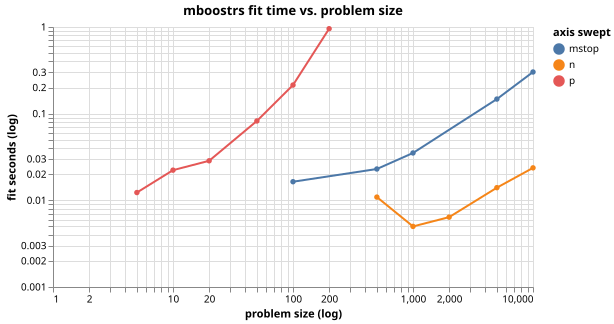

In [10]:
# Combine the three axes into one chart.
import altair as alt
all_scale = (n_scale.with_columns(pl.lit('n').alias('axis'))
             .vstack(p_scale.with_columns(pl.lit('p').alias('axis')))
             .vstack(m_scale.with_columns(pl.lit('mstop').alias('axis'))))
all_scale = all_scale.with_columns(
    pl.when(pl.col('axis') == 'n').then(pl.col('n'))
      .when(pl.col('axis') == 'p').then(pl.col('p'))
      .otherwise(pl.col('mstop')).alias('size'))

alt.Chart(all_scale).mark_line(point=True).encode(
    x=alt.X('size:Q', scale=alt.Scale(type='log'), title='problem size (log)'),
    y=alt.Y('seconds:Q', scale=alt.Scale(type='log'), title='fit seconds (log)'),
    color=alt.Color('axis:N', title='axis swept'),
    tooltip=['axis', 'size', 'seconds'],
).properties(width=480, height=260, title='mboostrs fit time vs. problem size')

## 3. Stability on near-singular designs

The boosting loop accumulates a risk trace (`model._risk`). For Gaussian
families the per-step risk is the residual sum of squares and is provably
monotone non-increasing (line search minimises it). For non-Gaussian
families the per-step risk is the deviance and the line search still
minimises it each step at the current ngradient, so a monotone trace is the
default behaviour, not a guarantee that nothing is wrong elsewhere.

The actual fragility surface is design conditioning, not the risk formula.
Each block learner has to invert its design through `CachedCholesky`
(`linalg.rs`); a near-singular design makes that inverse unreliable and
the obvious symptoms are coefficient blow-up or NaN, **not** a rising risk
trace. The probe below stress-tests the engine with a degenerate,
near-collinear design and reports the signs that _would_ indicate failure.
It also defines the `risk_diverged` detector that `bench_interaction_search.py`
uses, so a reader can apply it to any fitted model.

In [11]:
def risk_diverged(risk, tol=1e-6):
    """True if risk increases on any step by more than tol * max(|r|).
    This is the same check bench_interaction_search.py uses. For Gaussian
    and most non-Gaussian families, a rising risk trace is a sign that
    either the line search or the family calibration has mis-fired."""
    if len(risk) < 2:
        return False
    diffs = np.diff(risk)
    threshold = tol * max(1.0, float(np.max(np.abs(risk))))
    return bool(np.any(diffs > threshold))

# Near-collinear design: columns 0 and 1 are duplicated within 1e-12 noise.
rng = np.random.default_rng(0)
X = rng.standard_normal((400, 4))
X = np.column_stack([X, X[:, 0] + 1e-12 * rng.standard_normal(400),
                        X[:, 1] + 1e-12 * rng.standard_normal(400)])
y = (rng.standard_normal(400) > 0.5).astype(int)  # almost-pure noise label
data = {f'f{j}': X[:, j] for j in range(X.shape[1])}
data['y'] = y.astype(float)

m = mb.gamboost('y ~ ' + ' + '.join(f'bbs(f{j}, df=4)' for j in range(X.shape[1])),
                data=data, family=mb.Binomial(),
                control=mb.boost_control(300, 0.1))

risk = np.asarray(m._risk)
coefs = m._coefficients
fitted = np.asarray(m.fitted())
max_coef = max((float(np.max(np.abs(np.asarray(c)))) for c in coefs if len(c) > 0),
               default=0.0)
any_nan = any(np.any(np.isnan(np.asarray(c))) for c in coefs if len(c) > 0)
any_inf = any(np.any(np.isinf(np.asarray(c))) for c in coefs if len(c) > 0)

diag = pl.DataFrame([{
    'risk_monotone_up': risk_diverged(risk),
    'any_nan_coef': any_nan,
    'any_inf_coef': any_inf,
    'max_abs_coef': round(max_coef, 3),
    'fitted_min': round(float(fitted.min()), 3),
    'fitted_max': round(float(fitted.max()), 3),
    'risk_min': round(float(risk.min()), 3),
    'risk_max': round(float(risk.max()), 3),
}])
display(diag)
print('On this near-singular design Cholesky stays finite. Selection is')
print('absorbed by the duplicated copies: tune #1 and #2 (via m._selected offset).')

risk_monotone_up,any_nan_coef,any_inf_coef,max_abs_coef,fitted_min,fitted_max,risk_min,risk_max
bool,bool,bool,f64,f64,f64,f64,f64
false,false,false,1.072,-2.107,0.12,216.991,235.268


On this near-singular design Cholesky stays finite. Selection is
absorbed by the duplicated copies: tune #1 and #2 (via m._selected offset).


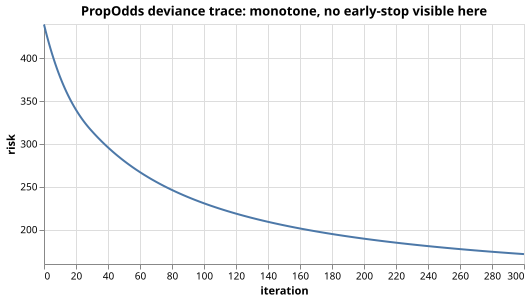

In [12]:
# Same check on a PropOdds (proportional-odds) family with the early-stopping
# sigma guard from `families.rs:PropOdds::calibrate` visible in the risk trace.
latent = X[:, 0] + 0.5 * X[:, 1] + 0.3 * rng.standard_normal(400)
y_ord = np.digitize(latent, np.quantile(latent, [0.33, 0.66])) + 1  # 1..3
data['y'] = y_ord.astype(float)
m_ord = mb.gamboost('y ~ ' + ' + '.join(f'bbs(f{j}, df=4)' for j in range(X.shape[1])),
                    data=data, family=mb.PropOdds(n_levels=3),
                    control=mb.boost_control(300, 0.1))
r_ord = np.asarray(m_ord._risk)
import altair as alt
trace = pl.DataFrame({'iteration': np.arange(len(r_ord)),
                      'risk': r_ord,
                      'family': 'PropOdds'})
alt.Chart(trace).mark_line().encode(
    x='iteration:Q',
    y=alt.Y('risk:Q', scale=alt.Scale(zero=False)),
).properties(width=480, height=240,
    title='PropOdds deviance trace: monotone, no early-stop visible here')

## 4. Interaction-search results

The interaction-search benchmark (`bench_interaction_search.py`) gives
mboostrs three modes: `additive` (main effects only), `screened` (rank
pairs, add the top 20 as base learners) and `all_pairs` (enter every
two-way interaction). The existing accuracy comparison shows that the
unrestricted tree ensembles (XGBoost, LightGBM, CatBoost) beat the additive
mboostrs fit by a wide margin on california (0.11) and a smaller margin on
electricity (0.06). The following results compare the interaction-aware
mboostrs variants with those additive and tree fits.

In [13]:
# Per-dataset mean score by variant.
inter_summary = (inter_runs.group_by('dataset', 'variant')
                 .agg(pl.col('score').mean().alias('mean_score'),
                      pl.col('n_pairs_selected').mean().alias('pairs_selected'),
                      pl.col('n_pairs_offered').mean().alias('pairs_offered'),
                      pl.col('total_seconds').mean().alias('total_seconds'))
                 .with_columns(pl.col('mean_score').round(4))
                 .sort('dataset', 'variant'))
display(inter_summary)

dataset,variant,mean_score,pairs_selected,pairs_offered,total_seconds
str,str,f64,f64,f64,f64
"""breast_cancer""","""additive""",0.9951,0.0,0.0,4.233333
"""breast_cancer""","""all_pairs""",0.9968,52.666667,435.0,376.91
"""breast_cancer""","""screened""",0.9897,3.666667,8.333333,17.9
"""california""","""additive""",0.7184,0.0,0.0,1.003333
"""california""","""all_pairs""",0.7587,25.333333,28.0,45.266667
…,…,…,…,…,…
"""diabetes""","""all_pairs""",0.487,15.333333,45.0,40.9
"""diabetes""","""screened""",0.4886,0.666667,1.333333,1.356667
"""electricity""","""additive""",0.8611,0.0,0.0,7.21


In [14]:
# Bring in the best-unrestricted tree score from the library comparison,
# so the gap to interactions is visible alongside how many pairs mboostrs
# actually selected.
best_tree = (lib_runs.filter(pl.col('mode') == 'configs',
                            pl.col('library').is_in(['XGBoost', 'LightGBM', 'CatBoost']))
             .group_by('dataset').agg(pl.col('score').max().alias('best_tree')))

additive = (inter_runs.filter(pl.col('variant') == 'additive')
            .group_by('dataset').agg(pl.col('score').mean().alias('additive')))

all_pairs = (inter_runs.filter(pl.col('variant') == 'all_pairs')
             .group_by('dataset').agg(pl.col('score').mean().alias('all_pairs')))

screened = (inter_runs.filter(pl.col('variant') == 'screened')
            .group_by('dataset').agg(pl.col('score').mean().alias('screened')))

combined = (additive.join(screened, on='dataset')
            .join(all_pairs, on='dataset')
            .join(best_tree, on='dataset')
            .with_columns(
                (pl.col('all_pairs') - pl.col('additive')).alias('gain from all_pairs'),
                (pl.col('best_tree') - pl.col('additive')).alias('gap to tree ensemble'))
            .with_columns(pl.exclude('dataset').round(4))
            .sort('gap to tree ensemble', descending=True))
display(combined)

dataset,additive,screened,all_pairs,best_tree,gain from all_pairs,gap to tree ensemble
str,f64,f64,f64,f64,f64,f64
"""california""",0.7184,0.7495,0.7587,0.833,0.0403,0.1146
"""electricity""",0.8611,0.8672,0.8737,0.9309,0.0126,0.0699
"""credit_g""",0.7893,0.781,0.7715,0.8002,-0.0178,0.0109
"""cpu_act""",0.9805,0.9835,0.9851,0.9861,0.0045,0.0055
"""breast_cancer""",0.9951,0.9897,0.9968,0.9996,0.0017,0.0045
"""diabetes""",0.4947,0.4886,0.487,0.4904,-0.0078,-0.0044


**What the numbers show.** On california the `all_pairs` mean score is 0.759
against the additive 0.718, and on electricity 0.874 against 0.861 ; the
`pairs_selected` column shows that the final refits select pair learners: on
average 25.3 of the 28 offered pairs on california and 18.3 of the 91 offered on
electricity. The `all_pairs` fits therefore contain interaction terms, and the
difference from the additive fit includes both those terms and the different
`mstop`/`nu`/`df` configuration that the inner cross-validation chose once pair
terms were available; the table does not separate the two.

Where pair learners are actually selected, the table is less favourable, not
more: on credit_g, `all_pairs` offers 1,653 pair terms against 750 training
rows, about 30 are selected, and the score drops from 0.789 to 0.772. Every
offered term is scored on every iteration, so unused terms cost wall-clock
while the selected few overfit a small training set. `screened` caps the
offer and recovers most of the drop (0.781) without beating additive. On
breast_cancer `all_pairs` selects about 53 of 435 pairs and the AUC rises from
0.995 to 0.997.

The `gap to tree ensemble` column is where interaction content shows, and on
california it is large (0.833 against 0.718 additive, a gap of 0.115). Selecting
tensor pairs closes 0.040 of it (0.759). One possible explanation for the remainder is that a
`bbs %X% bbs` term is a smooth product surface. A tree represents a threshold
with a few splits; a penalised smooth basis represents the same step with
many basis functions while a second-difference penalty suppresses exactly
that shape. When the residual interaction is a step or a kink, the tensor
fits it poorly. This benchmark does not test that explanation. Which interactions the tree ensembles actually exploit
on california is not identified by this table — the hypothesis that the
geographic pair dominates is tested separately in
`library_comparison_interactions.ipynb`, where a `btree(Lat, Lon)` term is
fitted directly.

Two protocol caveats bound these numbers. The interaction runs cap `mstop`
at 1500 and subsample to 5000 rows; section 1.1 measures both choices —
the mstop cap binds at 20000 rows (the winning configuration there uses
3000) but not at 5000, and the row cap compresses the additive-to-tree gap
most at small row counts.

The contrast with synthetic designs is systematic, not incidental. In §2's
scaling probes and the methodology chapters, the data-generating interaction
is a smooth product of marginals — exactly the shape a tensor basis
represents — and tensor terms dominate there by construction. On the six
real datasets in this table, offered tensors are selected on every dataset, and
the held-out change from offering all pairs is +0.040 on california, +0.013 on
electricity, +0.005 on cpu_act and +0.002 on breast_cancer, and −0.018 on credit_g
and −0.008 on diabetes. A conclusion about learner quality drawn from a synthetic
DGP does not transfer to these datasets; the held-out change with the pairs
offered is the transferable measurement.


In [15]:
# Wall-clock cost of offering interactions vs. not.
cost = (inter_runs.group_by(['dataset', 'variant'])
        .agg(pl.col('total_seconds').mean().alias('total_seconds'),
             pl.col('screen_seconds').mean().alias('screen_seconds'))
        .with_columns(pl.col('total_seconds').round(1),
                      pl.col('screen_seconds').round(3))
        .sort('dataset', 'variant'))
display(cost)

dataset,variant,total_seconds,screen_seconds
str,str,f64,f64
"""breast_cancer""","""additive""",4.2,0.0
"""breast_cancer""","""all_pairs""",376.9,0.0
"""breast_cancer""","""screened""",17.9,0.048
"""california""","""additive""",1.0,0.0
"""california""","""all_pairs""",45.3,0.0
…,…,…,…
"""diabetes""","""all_pairs""",40.9,0.0
"""diabetes""","""screened""",1.4,0.005
"""electricity""","""additive""",7.2,0.0


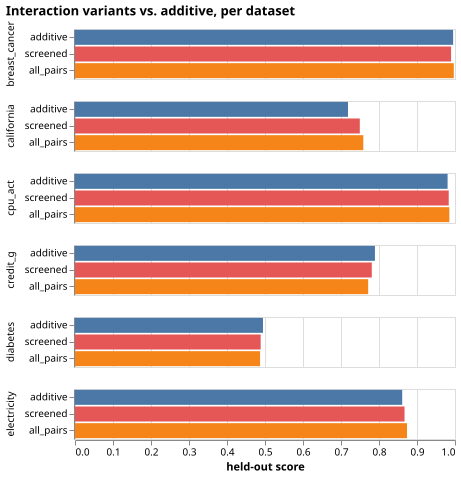

In [16]:
# Visualise: gain vs. cost.
import altair as alt
gain_cost = (inter_runs.group_by(['dataset', 'variant'])
             .agg(pl.col('score').mean().alias('score'),
                  pl.col('total_seconds').mean().alias('seconds'))
             .with_columns(pl.col('score').round(4), pl.col('seconds').round(1)))

alt.Chart(gain_cost).mark_bar().encode(
    x=alt.X('score:Q', title='held-out score', scale=alt.Scale(zero=False)),
    y=alt.Y('variant:N', sort=['additive', 'screened', 'all_pairs'], title=None),
    color=alt.Color('variant:N', legend=None),
    row=alt.Row('dataset:N', title=None),
    tooltip=['dataset', 'variant', 'score', 'seconds'],
).properties(width=380, height=50,
    title='Interaction variants vs. additive, per dataset')

## 5. Known limitations exercised as probes

The following limitations are documented in `AGENTS.md`. Rather than
describing them, each is shown here as a minimal snippet so the failure mode
is observable and the user can see what message appears, what does not
break, and what the working alternative is.

### 5.1 Binomial coding {-1, +1} and the doubled inverse link

User-supplied labels enter the Python layer as {0, 1} and are remapped to
{-1, +1} internally (gotcha 1). The inverse link compensates with
sigmoid(2*eta) (gotcha 1, `families.py:_inverse_link`). The practical
effect: `predict_proba` (sklearn wrapper) is calibrated, but the **raw
gamboost `predict()` output is on the link-half scale** and must be run
through sigmoid(2*eta) to produce class probabilities.

In [17]:
rng = np.random.default_rng(0)
X = rng.standard_normal((400, 4))
y = (X[:, 0] + 0.3 * X[:, 1] + rng.standard_normal(400) * 0.5 > 0).astype(int)

# Raw gamboost API: predict() is on the {-1,+1} margin, scaled eta/2.
data = {f'f{j}': X[:, j] for j in range(X.shape[1])}
data['y'] = y.astype(float)
m = mb.gamboost('y ~ ' + ' + '.join(f'bbs(f{j}, df=3)' for j in range(4)),
                data=data, family=mb.Binomial(),
                control=mb.boost_control(200, 0.1))
raw = np.asarray(m.predict())

# sklearn wrapper: predict_proba is calibrated.
from mboostrs.sklearn import GAMBoostClassifier
clf = GAMBoostClassifier(mstop=200, nu=0.1).fit(X, y)
proba = clf.predict_proba(X)[:, 1]
p_from_raw = 1.0 / (1.0 + np.exp(-2.0 * raw))

print(f'raw predict range        : [{raw.min():.3f}, {raw.max():.3f}]')
print(f'sklearn proba range      : [{proba.min():.3f}, {proba.max():.3f}]')
print(f'sigmoid(2 * raw) range   : [{p_from_raw.min():.3f}, {p_from_raw.max():.3f}]')
print()
print('The doubled inverse link relationship holds: sigmoid(2 * raw_predict)')
print('matches predict_proba. Use the sklearn wrapper or apply the doubling')
print('manually so a downstream threshold sees probabilities, not link-thirds.')

raw predict range        : [-3.281, 3.154]
sklearn proba range      : [0.005, 0.997]
sigmoid(2 * raw) range   : [0.001, 0.998]

The doubled inverse link relationship holds: sigmoid(2 * raw_predict)
matches predict_proba. Use the sklearn wrapper or apply the doubling
manually so a downstream threshold sees probabilities, not link-thirds.


### 5.2 `center=TRUE` predict with newdata (gotcha 23)

A `bbs(center=TRUE)` fit returns `p - d` coefficients where a
`center=FALSE` fit would return `p`. The R-side predict path can silently
drop these predictions because the coef-vector length disagrees with the
rebuilt design's column count. The Python `LearnerStore.predict` path is
**unaffected**, which is why the check below uses `predict(newdata=...)`
on the Python side — it works because Python goes through the Rust
LearnerStore, not the R predict reconstruction.

In [18]:
X, y = load_diabetes(return_X_y=True)
data = {f'f{j}': X[:, j] for j in range(X.shape[1])}; data['y'] = y.astype(float)
m_center = mb.gamboost('y ~ bbs(f0, df=4, center=True)', data=data,
                       family=mb.Gaussian(), control=mb.boost_control(100, 0.1))
m_no_center = mb.gamboost('y ~ bbs(f0, df=4, center=False)', data=data,
                         family=mb.Gaussian(), control=mb.boost_control(100, 0.1))

nd = {f'f{j}': X[:5, j] for j in range(X.shape[1])}
pred_c = np.asarray(m_center.predict(newdata=nd)).ravel()[:5]
pred_nc = np.asarray(m_no_center.predict(newdata=nd)).ravel()[:5]
print('center=True  predict(newdata) ok:', np.round(pred_c, 2).tolist())
print('center=False predict(newdata) ok:', np.round(pred_nc, 2).tolist())
print()
print('Python path works. The gotcha only bites the R-side predict, which')
print('rebuilds the design and silently skips the learner when coef len != ncol.')

center=True  predict(newdata) ok: [169.42, 144.89, 160.46, 140.23, 149.64]
center=False predict(newdata) ok: [167.86, 146.61, 175.8, 130.26, 150.6]

Python path works. The gotcha only bites the R-side predict, which
rebuilds the design and silently skips the learner when coef len != ncol.


### 5.3 Buser shape validation (gotcha 19)

`Buser` (a user-supplied design + penalty learner) accepts raw arrays with no
shape checks in the formula layer. A non-square `K` or `X/K` dimension
mismatch propagates to the Rust engine, where it produces a `PanicException`
that PyO3 converts to a Python exception. The wrapper in `learners.py` is
supposed to do this validation early — this probe checks whether it does.

Note: `Buser` is one of the learners the formula string cannot fully express
on its own. The formula token is lower-case `buser(...)`; the arrays `X` and
`K` named in the formula are pulled from the `env=` dict of the `gamboost()`
call, not from `data=` (which carries only the response and the column
variables). The capitalised `Buser` is the Python class returned by the
`mboostrs.learners` module.

In [19]:
rng = np.random.default_rng(0)
X = rng.standard_normal((200, 3))
y = X[:, 0] + rng.standard_normal(200) * 0.1
data = {'y': y.astype(float), 'dummy': np.zeros(200)}  # formula needs a y col
data['Xu'] = X[:, :2]
data['K_wrong'] = np.eye(3)   # should be (2,2) to match Xu's column count
data['K_ok'] = np.eye(2)

# Buser binds X and K via the `env` kwarg, not via `data`. Lower-case `buser`
# is the formula tokeniser's spelling (the capitalised `Buser` is the class).
# Wrong K: should raise a *clean* ValueError, not a PanicException.
try:
    mb.gamboost('y ~ buser(u, X=Xu, K=K_wrong, df=4)',
                data=data, env={'Xu': data['Xu'], 'K_wrong': data['K_wrong']},
                family=mb.Gaussian(),
                control=mb.boost_control(20, 0.1))
    print('Wrong K accepted — validation missing.')
except ValueError as e:
    print('ValueError (clean):', str(e)[:90])
except Exception as e:
    print(f'{type(e).__name__} (unclean):', str(e)[:90])

# Correct K: fits. The design lives in `env`, outside `data`, so a new-data
# prediction has to be told where to find the new rows of the design: the
# `buser_newdata` argument maps the learner name to the new X matrix. Without
# it, predict() cannot rebuild the Buser design for unseen rows.
try:
    m = mb.gamboost('y ~ buser(u, X=Xu, K=K_ok, df=4)',
                    data=data, env={'Xu': data['Xu'], 'K_ok': data['K_ok']},
                    family=mb.Gaussian(),
                    control=mb.boost_control(20, 0.1))
    in_sample = np.asarray(m.predict())
    on_new = np.asarray(m.predict(newdata=data,
                                  buser_newdata={'u': data['Xu']},
                                  type='link'))
    print('Correct K fits. Training predictions:',
          np.round(in_sample[:3], 2).tolist())
    print('newdata + buser_newdata reproduces fitted_:',
          bool(np.allclose(on_new, m.fitted_, rtol=1e-10)))
except Exception as e:
    print(f'Buser (correct K) {type(e).__name__}:', str(e)[:90])

ValueError (clean): Buser K must have 2 rows, got 3
Correct K fits. Training predictions: [0.04, 0.03, 1.06]
newdata + buser_newdata reproduces fitted_: True


### 5.4 Survival family AIC raises `NotImplementedError` (gotcha 16)

AIC requires a dispersion parameter, which none of the survival families
(CoxPH, Loglog, Lognormal, Weibull) have. Both `GLMBoostModel.aic()` and
`GAMBoostModel.aic()` raise on a survival family. This is a deliberate
guard against an invalid number, not a missing feature.

In [20]:
try:
    from mboostrs import CoxPH
    rng = np.random.default_rng(0)
    n = 300
    t = rng.exponential(scale=10, size=n)
    e = (rng.random(n) < 0.6).astype(int)
    data = {'time': t, 'event': e.astype(float)}
    for j in range(3):
        data[f'f{j}'] = rng.standard_normal(n)
    m = mb.glmboost('Surv(time, event) ~ ' + ' + '.join(f'bols(f{j})' for j in range(3)),
                    data=data, family=CoxPH(),
                    control=mb.boost_control(50, 0.1))
    try:
        m.aic()
        print('CoxPH aic returned a number — guard missing.')
    except NotImplementedError as e:
        print('CoxPH aic NotImplementedError (expected):', str(e)[:80])
except Exception as e:
    print(f'CoxPH setup {type(e).__name__}:', str(e)[:90])

CoxPH aic NotImplementedError (expected): aic() is not available for survival families: the hat-matrix degrees of freedom 


### 5.5 Weights-length mismatch reaches the Rust engine (gotcha 11)

`glmboost()` and `gamboost()` are supposed to validate `len(weights) == n`
in pure Python before the Rust call. If that validation is skipped, a
length mismatch hits an ndarray assertion in Rust and surfaces as a
`PanicException` rather than a clean Python `ValueError`. This probe
verifies which one appears on this build.

In [21]:
rng = np.random.default_rng(0)
n = 200
X = rng.standard_normal((n, 3))
y = X[:, 0] + rng.standard_normal(n) * 0.1
w_wrong = np.ones(n - 1)
data = {f'f{j}': X[:, j] for j in range(X.shape[1])}; data['y'] = y.astype(float)
try:
    mb.gamboost('y ~ ' + ' + '.join(f'bbs(f{j}, df=3)' for j in range(3)),
                data=data, family=mb.Gaussian(),
                control=mb.boost_control(50, 0.1), weights=w_wrong)
    print('Wrong-length weights accepted — validation missing.')
except ValueError as e:
    print('ValueError (clean):', str(e)[:90])
except Exception as e:
    # PanicException is the documented failure mode if the Python-side
    # check was bypassed by a future refactor.
    print(f'{type(e).__name__} (unclean):', str(e)[:90])

ValueError (clean): weights length 199 != n=200


### 5.6 `mstop` off-by-one risk indexing (gotcha 6)

`risk_[i]` is the risk **after** iteration $i$. `aic[mstop - 1]` is the
AIC at the optimal iteration. An off-by-one on either side silently
returns the wrong slice. The probe below fits a model and verifies that
the risk array's length is `mstop + 1` (it starts at the offset-only
model, iteration 0).

In [22]:
mg = mb.gamboost('y ~ bbs(f0, df=4) + bbs(f1, df=4) + bbs(f2, df=4)',
                data=data, family=mb.Gaussian(),
                control=mb.boost_control(50, 0.1))
risk = np.asarray(mg._risk)
n_selected = len(mg._selected)
print(f'mstop asked:    50')
print(f'risk array len: {len(risk)}  (expected mstop+1 = 51)')
print(f'#selected:      {n_selected}  (expected <= 50)')
print(f'risk[0] (offset-only): {risk[0]:.4f}')
print(f'risk[50] (final):      {risk[50]:.4f}')
assert len(risk) == 51, 'risk array should be mstop+1 (includes iteration 0)'
print('OK.')

mstop asked:    50
risk array len: 51  (expected mstop+1 = 51)
#selected:      50  (expected <= 50)
risk[0] (offset-only): 203.7230
risk[50] (final):      2.0051
OK.


## Scope of the diagnostics

It gives a working view of three things: how mboostrs scales with rows,
columns and iterations; how stable the engine is on near-singular designs;
and a concrete probe for each documented limitation in `AGENTS.md`.

It does **not** score mboostrs against the other libraries here — that is
the job of `library_comparison.ipynb`. It does **not** search for new bugs;
each probe is paired with the gotcha number from `AGENTS.md` so a reader
can trace behaviour back to the implementation.

Three protocol caveats bound what the numbers mean. First, every accuracy
table subsamples its dataset to 5000 rows; section 1.1 measures what that
cap does on california and how the additive-to-tree gap reads at 1000,
5000 and 20000 rows. Second, the interaction-search grid caps `mstop` at
1500, which understates the additive baseline relative to section 1.1's
extended grid. Third, the scaling and stability sections use synthetic
designs by construction; §4 shows the concrete failure of transferring
synthetic-dataset conclusions to real data (tensor pairs that dominate
smooth synthetic interactions raise the score by 0.040 of a 0.115 gap on
california and lower it on credit_g and diabetes). Absolute timings in §2 are
machine-specific and not portable; only the shape of the growth is.

Worked actions by failure mode:

* **§4 pairs selected, gap remains** (california, electricity): offering
  tensor pairs raises the score by 0.040 and 0.013, and the tree ensembles
  stay ahead by 0.074 and 0.057. For threshold-shaped interactions use tree
  ensembles, or supply a custom `Buser` basis whose shape matches the
  geometry.
* **§4 all_pairs regression on small n**: cap the offered pairs with the
  `screened` mode, or skip interactions entirely when $n < p^2$.
* **§3 coefficient NaN / inf or fitted range blow-up**: tighten `nu` (0.1
  is the project default for a reason), drop the collinear columns (the
  Gram path guards on conditioning, but `CachedCholesky` will still
  follow a singular design), or move to a `Bmono` / `Bconstrained` learner
  with a constraint matrix that pins the unidentifiable direction.
* **§5.1, §5.3, §5.5** clean-vs-unclean error paths: these probes verify
  that the documented Python-side validations are still in place; if any
  flips to `PanicException`, the corresponding pure-Python guard in
  `gamboost.py` / `glmboost.py` / `learners.py` has been bypassed and
  should be restored.